['Campaign_ID', 'Company', 'Campaign_Type', 'Target_Audience', 'Duration', 'Channel_Used', 'Conversion_Rate', 'Acquisition_Cost', 'ROI', 'Location', 'Language', 'Clicks', 'Impressions', 'Engagement_Score', 'Customer_Segment', 'Date']
Number of Rows: 22029
Number of Columns: 16
<class 'pandas.DataFrame'>
RangeIndex: 22029 entries, 0 to 22028
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Campaign_ID       22029 non-null  int64         
 1   Company           22029 non-null  str           
 2   Campaign_Type     22029 non-null  str           
 3   Target_Audience   22029 non-null  str           
 4   Duration          0 non-null      float64       
 5   Channel_Used      22029 non-null  str           
 6   Conversion_Rate   22029 non-null  float64       
 7   Acquisition_Cost  22029 non-null  int64         
 8   ROI               22029 non-null  float64       
 9   Location          22029 n

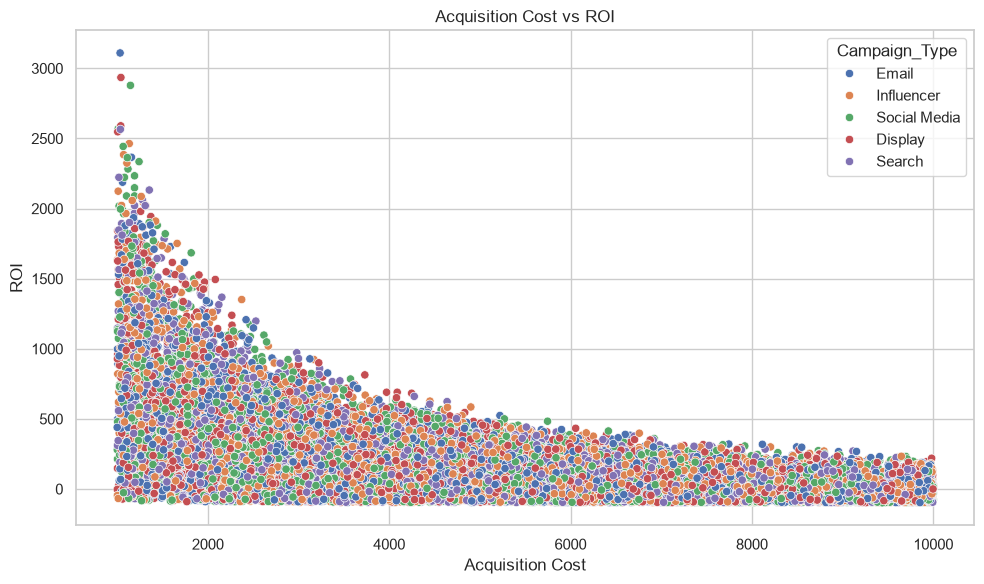

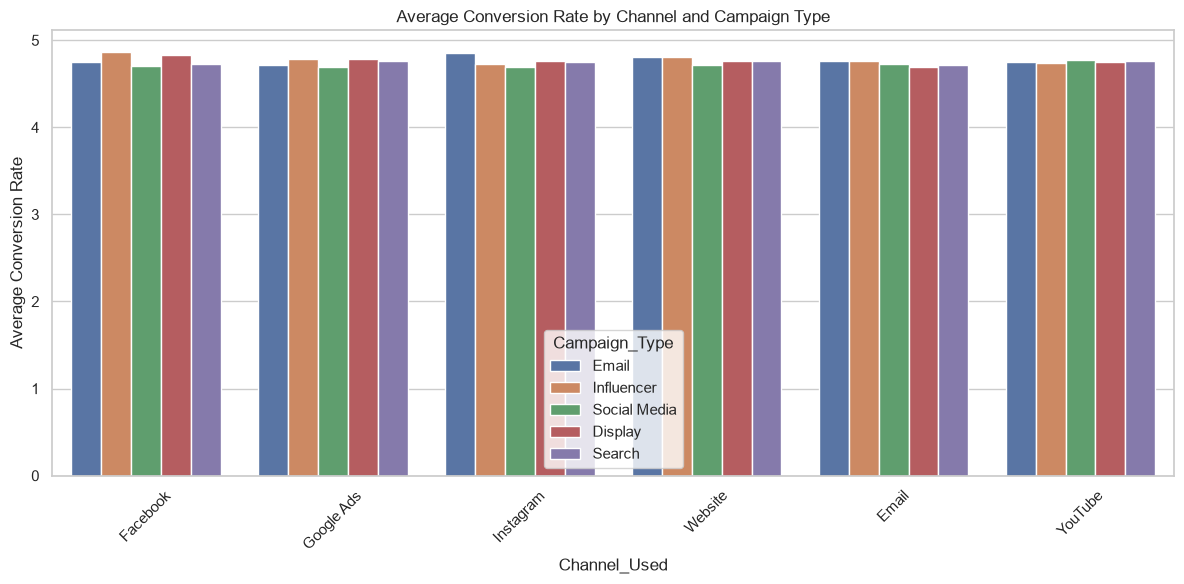

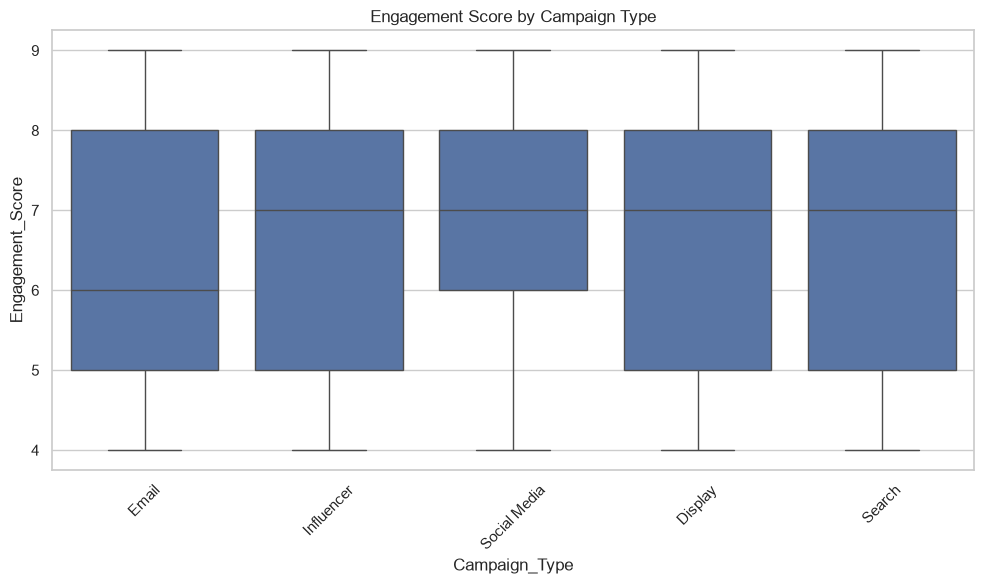

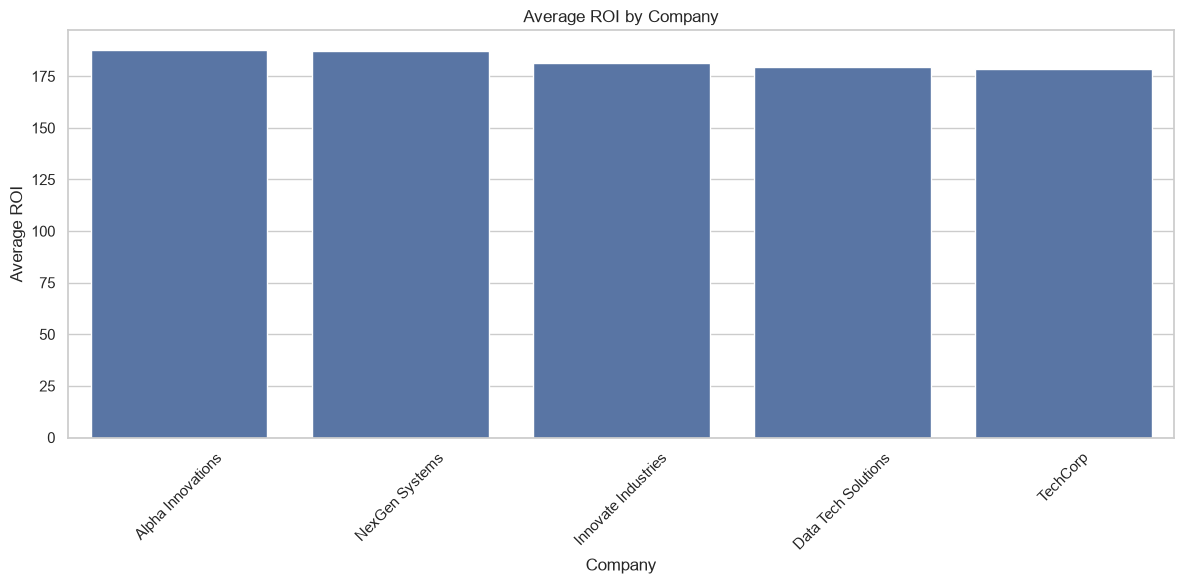

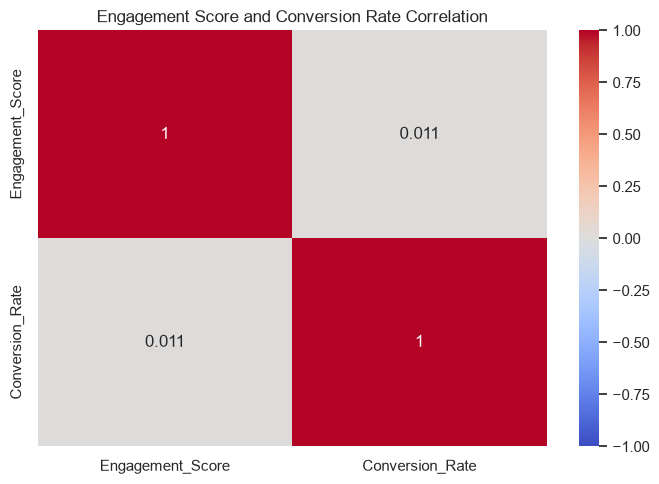

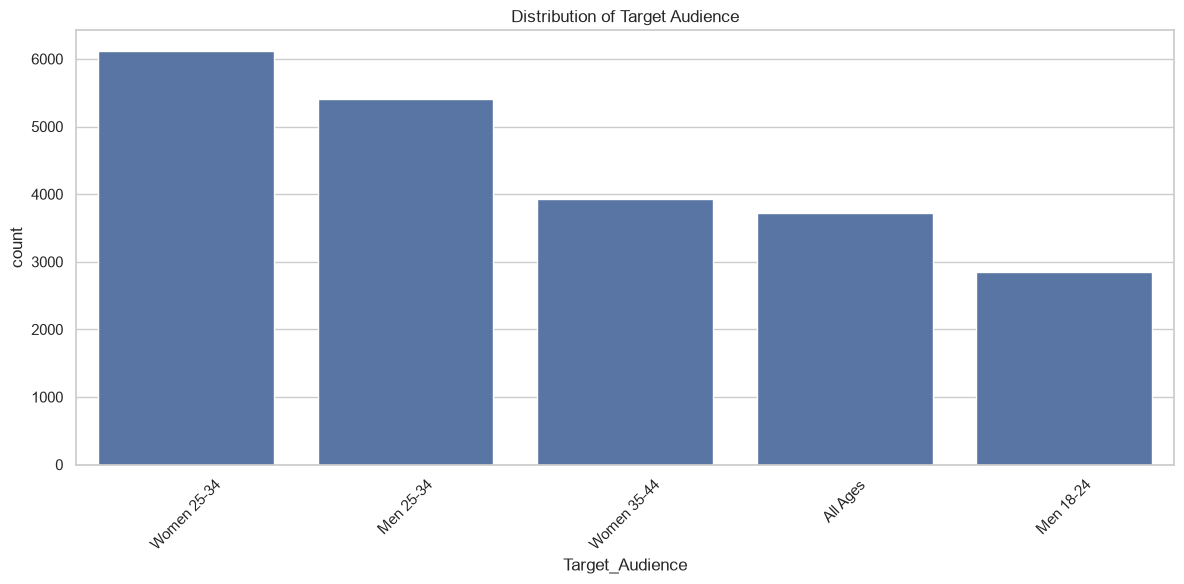

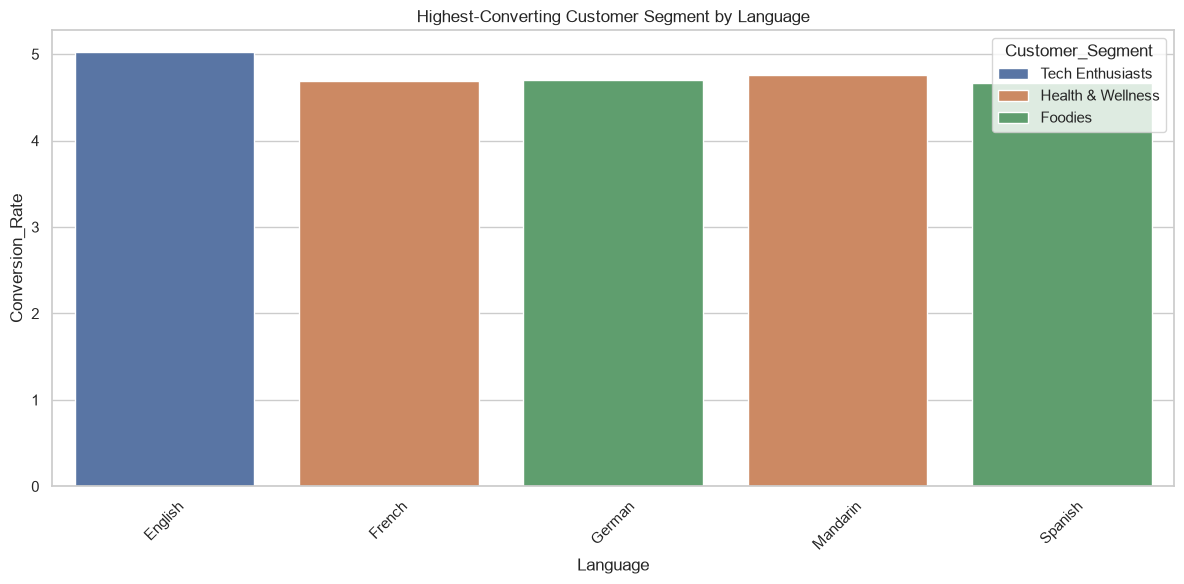

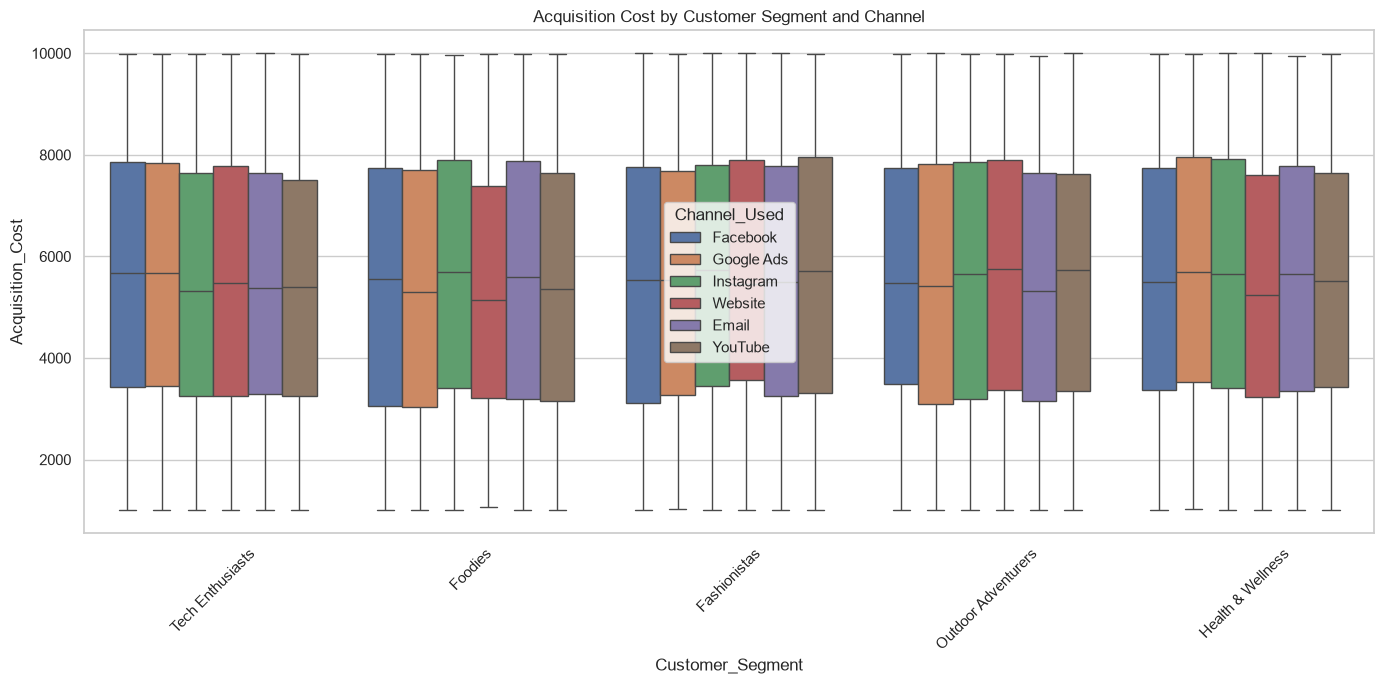

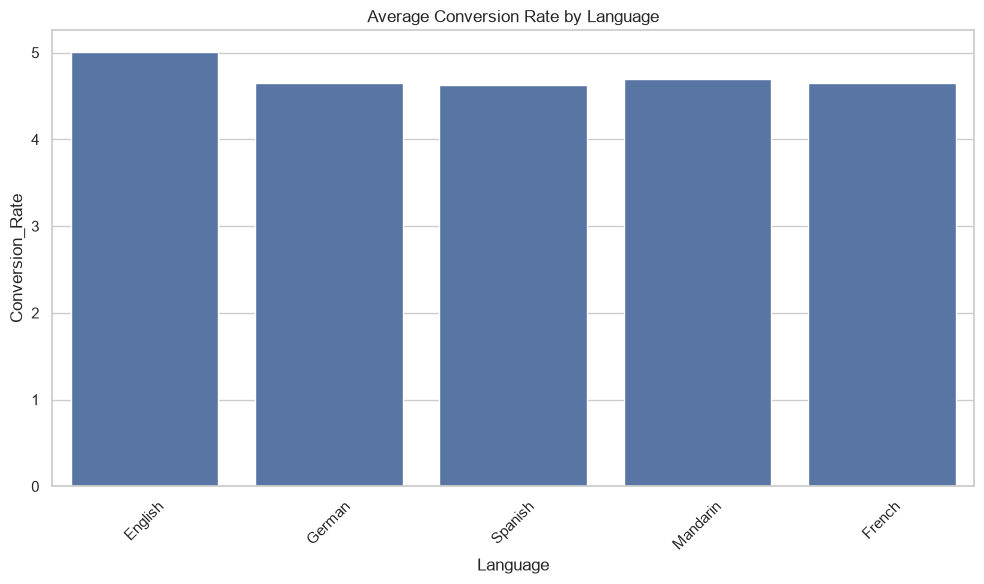

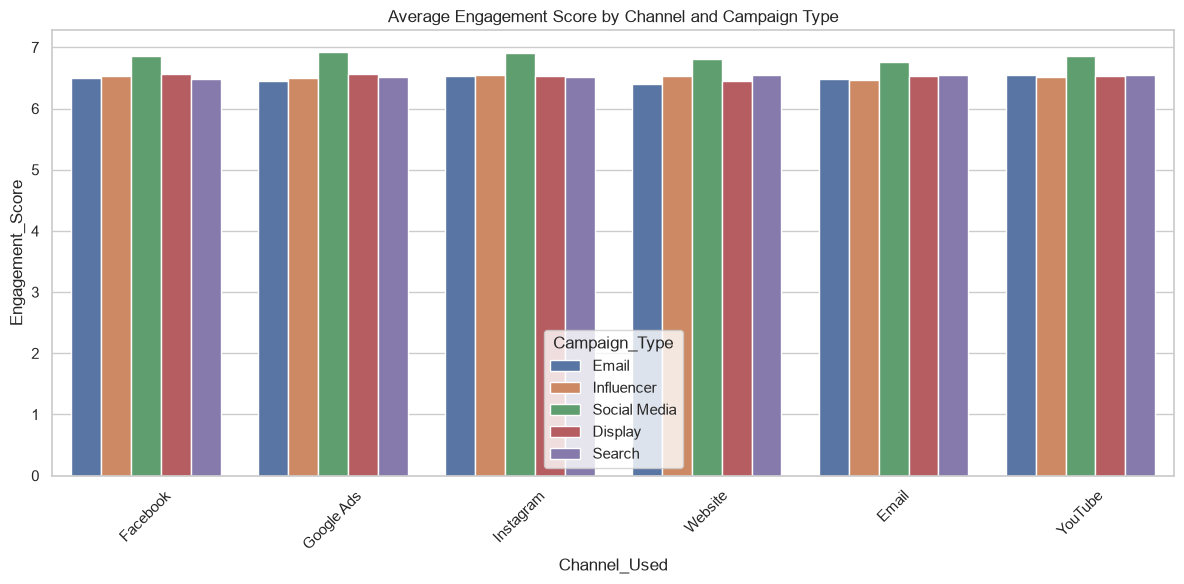

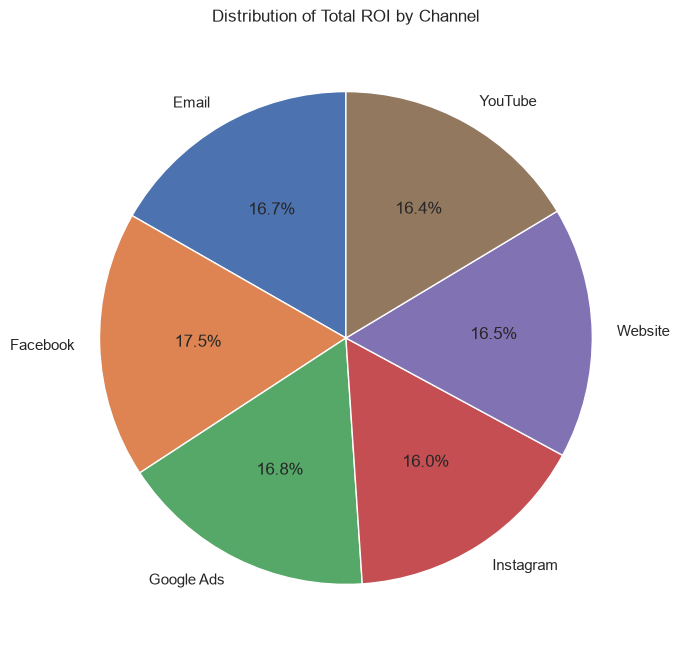

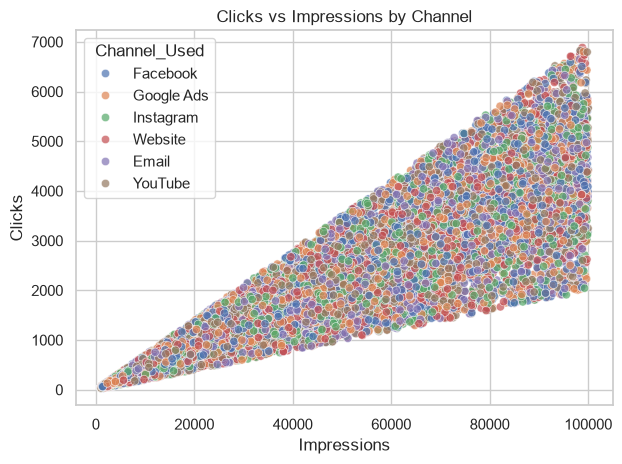

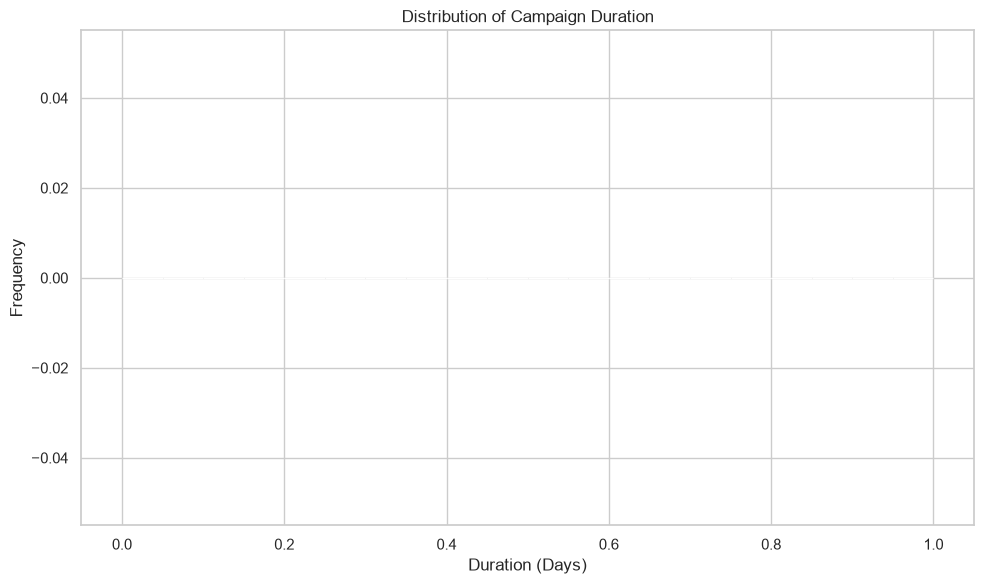

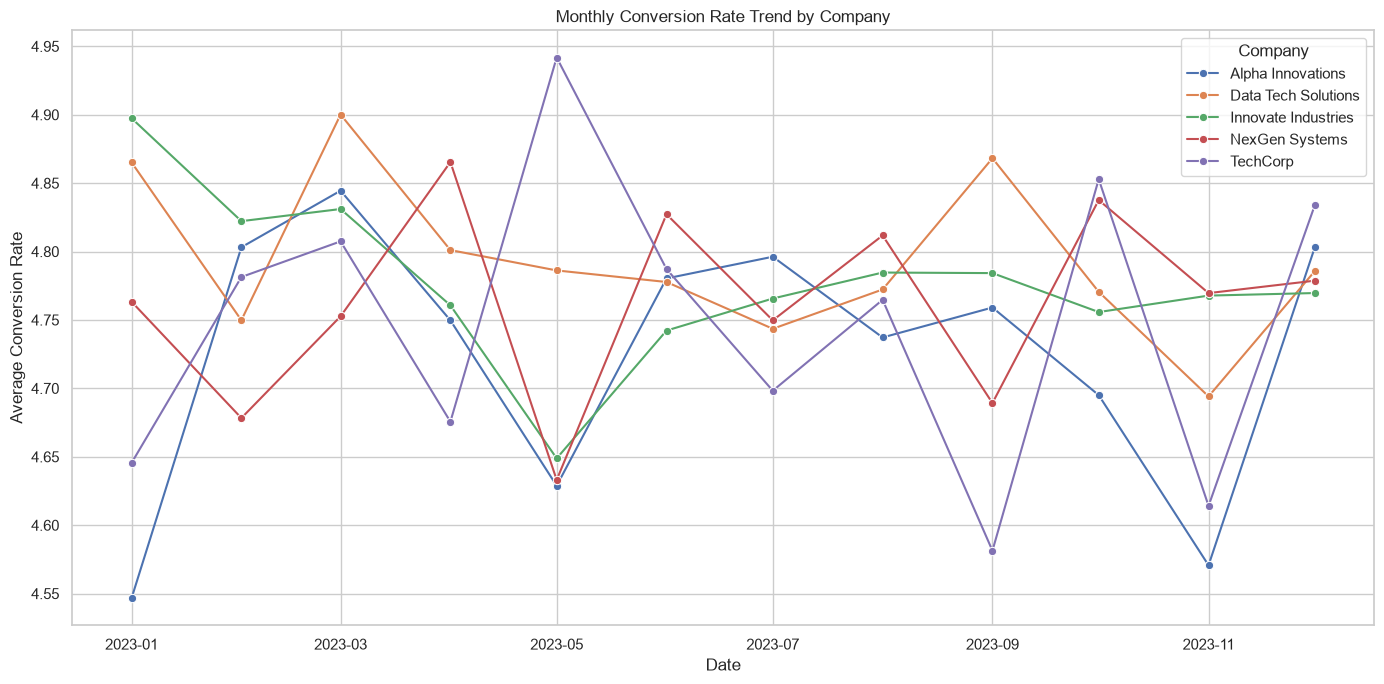

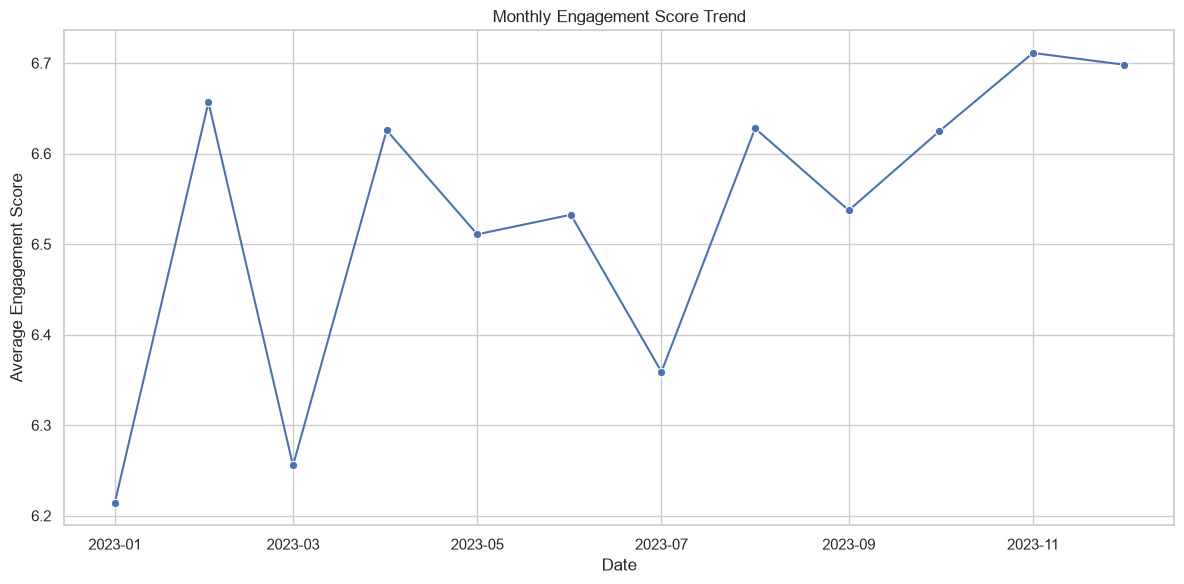

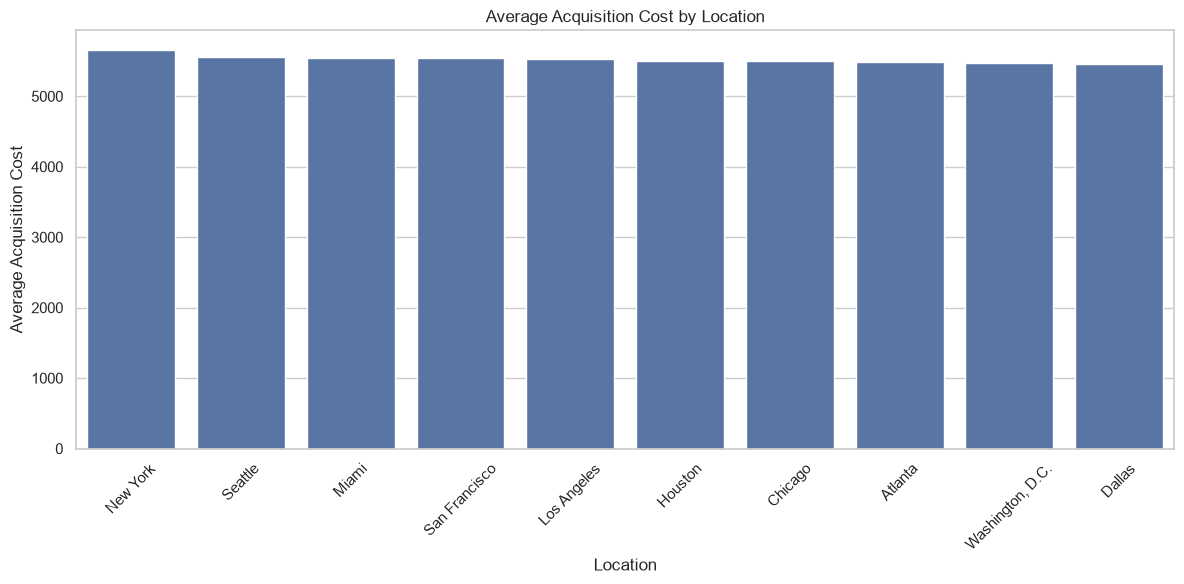

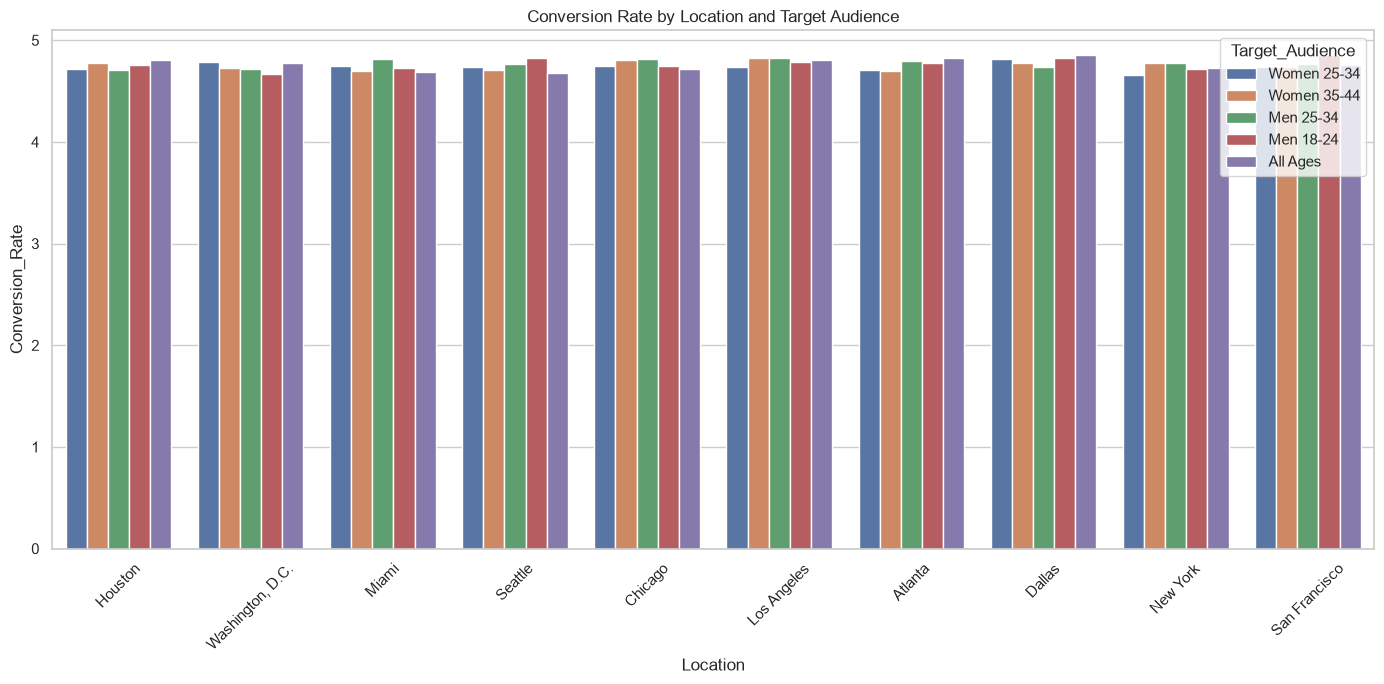

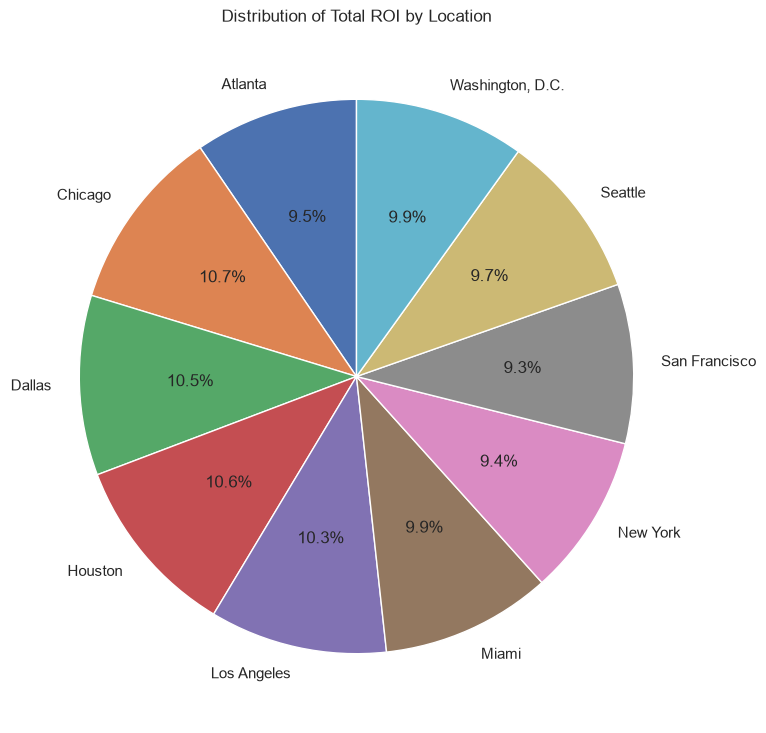

Total Campaigns: 22029
Average Conversion Rate: 4.76
Average ROI: 182.86
Average Acquisition Cost: 5522.74
Total Clicks: 48988257
Total Impressions: 1114896563
Average Engagement Score: 6.58
Overall CTR: 4.39 %


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("marketing_campaign_dataset.csv")

df.head()
print(df.columns.tolist())
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

numeric_columns = [
    "Duration", "Conversion_Rate", "Acquisition_Cost",
    "ROI", "Clicks", "Impressions", "Engagement_Score"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df.head()
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])
df.info()
df.describe()
print("Unique Campaign IDs:", df["Campaign_ID"].nunique())
print(df["Location"].unique())
print(df["Customer_Segment"].unique())
print(df["Campaign_Type"].value_counts())
print(df["Channel_Used"].value_counts())
print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Rows:", df.duplicated().sum())
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Acquisition_Cost",
    y="ROI",
    hue="Campaign_Type"
)

plt.title("Acquisition Cost vs ROI")
plt.xlabel("Acquisition Cost")
plt.ylabel("ROI")
plt.tight_layout()
plt.show()
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x="Channel_Used",
    y="Conversion_Rate",
    hue="Campaign_Type",
    estimator="mean",
    errorbar=None
)

plt.title("Average Conversion Rate by Channel and Campaign Type")
plt.xticks(rotation=45)
plt.ylabel("Average Conversion Rate")
plt.tight_layout()
plt.show()
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Campaign_Type",
    y="Engagement_Score"
)

plt.title("Engagement Score by Campaign Type")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
roi_company = (
    df.groupby("Company")["ROI"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=roi_company.index,
    y=roi_company.values
)

plt.title("Average ROI by Company")
plt.xlabel("Company")
plt.ylabel("Average ROI")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
correlation = df[
    ["Engagement_Score", "Conversion_Rate"]
].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Engagement Score and Conversion Rate Correlation")
plt.tight_layout()
plt.show()
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="Target_Audience",
    order=df["Target_Audience"].value_counts().index
)

plt.title("Distribution of Target Audience")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
segment_conversion = (
    df.groupby(["Language", "Customer_Segment"])["Conversion_Rate"]
    .mean()
    .reset_index()
)

highest_segments = segment_conversion.loc[
    segment_conversion.groupby("Language")["Conversion_Rate"].idxmax()
]

plt.figure(figsize=(12, 6))

sns.barplot(
    data=highest_segments,
    x="Language",
    y="Conversion_Rate",
    hue="Customer_Segment"
)

plt.title("Highest-Converting Customer Segment by Language")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df,
    x="Customer_Segment",
    y="Acquisition_Cost",
    hue="Channel_Used"
)

plt.title("Acquisition Cost by Customer Segment and Channel")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="Language",
    y="Conversion_Rate",
    estimator="mean",
    errorbar=None
)

plt.title("Average Conversion Rate by Language")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x="Channel_Used",
    y="Engagement_Score",
    hue="Campaign_Type",
    errorbar=None
)

plt.title("Average Engagement Score by Channel and Campaign Type")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
roi_channel = df.groupby("Channel_Used")["ROI"].sum()

if (roi_channel >= 0).all() and roi_channel.sum() > 0:
    plt.figure(figsize=(8, 8))

    plt.pie(
        roi_channel,
        labels=roi_channel.index,
        autopct="%1.1f%%",
        startangle=90
    )

    plt.title("Distribution of Total ROI by Channel")
    plt.show()
else:
    print("Pie chart is not suitable because ROI totals include negative values or have no positive total.")
    plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df,
    x="Impressions",
    y="Clicks",
    hue="Channel_Used",
    alpha=0.7
)

plt.title("Clicks vs Impressions by Channel")
plt.xlabel("Impressions")
plt.ylabel("Clicks")
plt.tight_layout()
plt.show()
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Duration",
    bins=20,
    kde=True
)

plt.title("Distribution of Campaign Duration")
plt.xlabel("Duration (Days)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()
monthly_conversion = (
    df.dropna(subset=["Date"])
    .groupby([
        pd.Grouper(key="Date", freq="MS"),
        "Company"
    ])["Conversion_Rate"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=monthly_conversion,
    x="Date",
    y="Conversion_Rate",
    hue="Company",
    marker="o"
)

plt.title("Monthly Conversion Rate Trend by Company")
plt.xlabel("Date")
plt.ylabel("Average Conversion Rate")
plt.tight_layout()
plt.show()
monthly_engagement = (
    df.dropna(subset=["Date"])
    .groupby(pd.Grouper(key="Date", freq="MS"))["Engagement_Score"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_engagement,
    x="Date",
    y="Engagement_Score",
    marker="o"
)

plt.title("Monthly Engagement Score Trend")
plt.xlabel("Date")
plt.ylabel("Average Engagement Score")
plt.tight_layout()
plt.show()
location_cost = (
    df.groupby("Location")["Acquisition_Cost"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=location_cost.index,
    y=location_cost.values
)

plt.title("Average Acquisition Cost by Location")
plt.xticks(rotation=45)
plt.ylabel("Average Acquisition Cost")
plt.tight_layout()
plt.show()
plt.figure(figsize=(14, 7))

sns.barplot(
    data=df,
    x="Location",
    y="Conversion_Rate",
    hue="Target_Audience",
    errorbar=None
)

plt.title("Conversion Rate by Location and Target Audience")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
location_roi = df.groupby("Location")["ROI"].sum()

if (location_roi >= 0).all() and location_roi.sum() > 0:
    plt.figure(figsize=(9, 9))

    plt.pie(
        location_roi,
        labels=location_roi.index,
        autopct="%1.1f%%",
        startangle=90
    )

    plt.title("Distribution of Total ROI by Location")
    plt.show()
else:
    print("Pie chart is not suitable for these ROI totals.")
print("Total Campaigns:", df["Campaign_ID"].nunique())

print("Average Conversion Rate:",
      round(df["Conversion_Rate"].mean(), 2))

print("Average ROI:",
      round(df["ROI"].mean(), 2))

print("Average Acquisition Cost:",
      round(df["Acquisition_Cost"].mean(), 2))

print("Total Clicks:", df["Clicks"].sum())

print("Total Impressions:", df["Impressions"].sum())

print("Average Engagement Score:",
      round(df["Engagement_Score"].mean(), 2))

total_impressions = df["Impressions"].sum()

if total_impressions > 0:
    ctr = df["Clicks"].sum() / total_impressions * 100
    print("Overall CTR:", round(ctr, 2), "%")